## Climate Hazard Dataset Exploration

#### Flood Hazard Dataset Exploration & Selection

**Project:** AI-Powered Climate Risk Intelligence Platform for Multi-Sector Decision Support in Germany

**Notebook:** 02_climate_dataset_exploration_flood_proxy_rx5day.ipynb

**Dataset:** Rx5day (Maximum Consecutive Five-Day Precipitation)

**Description:** Rx5day represents the annual maximum precipitation accumulated over any five consecutive days. It is a widely used climate extreme indicator for assessing extreme precipitation events and flood hazard potential.

**Purpose:** Selected as the flood hazard proxy for AI-based Climate & ESG Risk Intelligence because prolonged extreme rainfall is a primary driver of river flooding and catchment-scale flood risk.

**Hazard type:** Extreme precipitation / flood proxy

**Spatial focus:** Germany

**Temporal focus:** 1990–2025

**Objective**

To explore, evaluate, and preprocess the Maximum Consecutive Five-Day Precipitation (Rx5day) dataset for Germany and determine its suitability as a flood hazard proxy within the Climate Risk Intelligence Platform.

This notebook documents dataset characteristics, quality assessment, preprocessing decisions, visualization, and preparation for integration into the master climate hazard database.

### Import Libraries

In [1]:
# =======================================================
# Climate Risk Intelligence Germany
# Dataset Exploration 02
# Dataset: Maximum Consecutive Five-Day Precipitation (Rx5day)
# Hazard proxy: Flood / extreme precipitation
# Author: Purity Mbaabu
# =======================================================

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

### Locate Dataset

In [2]:
# =======================================================
# Locate NetCDF dataset
# =======================================================


from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

flood_file = PROJECT_ROOT / "data" / "incoming" / "climate" / "13_maximum_five_days_precipitation-reanalysis-yearly-layer-nuts_2-latitude-1940-2025-v2.0.nc"

print(flood_file)
print(flood_file.exists())

d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany\data\incoming\climate\13_maximum_five_days_precipitation-reanalysis-yearly-layer-nuts_2-latitude-1940-2025-v2.0.nc
True


### Load Dataset

In [ ]:
# =======================================================
# Load NetCDF dataset
# =======================================================

ds_flood = xr.open_dataset(flood_file)

ds_flood



<xarray.Dataset> Size: 237kB
Dimensions:                         (nuts: 340, time: 86)
Coordinates:
  * nuts                            (nuts) object 3kB 'ITC4' 'ITF1' ... 'UKI6'
  * time                            (time) datetime64[ns] 688B 1940-01-01 ......
    realization                     int64 8B ...
Data variables:
    maximum_five_day_precipitation  (nuts, time) float64 234kB ...

### Inspect Dataset

##### Step 1. Explore the variable

In [4]:
# =======================================================
# Inspect available variables
# =======================================================

list(ds_flood.data_vars)

['maximum_five_day_precipitation']

##### Step 2. Explore the variable metadata

In [6]:
# =======================================================
# Inspect variable metadata
# =======================================================

ds_flood["maximum_five_day_precipitation"].attrs

{'reduce_dims': ['lat', 'lon'],
 'long_name': 'Total precipitation',
 'units': 'mm',
 'standard_name': 'lwe_thickness_of_precipitation_amount',
 'comment': 'derived from 3 hourly ERA5 reanalysis',
 'type': 'real',
 'accumulated_since': 'start of timestep'}

##### Step 3. Look at actual values

In [7]:
# =======================================================
# Inspect variable values
# =======================================================

ds_flood["maximum_five_day_precipitation"]

<xarray.DataArray 'maximum_five_day_precipitation' (nuts: 340, time: 86)> Size: 234kB
[29240 values with dtype=float64]
Coordinates:
  * nuts         (nuts) object 3kB 'ITC4' 'ITF1' 'ITF2' ... 'UKI4' 'UKI5' 'UKI6'
  * time         (time) datetime64[ns] 688B 1940-01-01 1941-01-01 ... 2025-01-01
    realization  int64 8B ...
Attributes:
    reduce_dims:        ['lat', 'lon']
    long_name:          Total precipitation
    units:              mm
    standard_name:      lwe_thickness_of_precipitation_amount
    comment:            derived from 3 hourly ERA5 reanalysis
    type:               real
    accumulated_since:  start of timestep

##### Step 4. Summary statistics

In [8]:
# =======================================================
# Generate summary statistics
# =======================================================

flood = ds_flood["maximum_five_day_precipitation"]

print(f"Minimum           : {flood.min().values:.3f}")
print(f"Maximum           : {flood.max().values:.3f}")
print(f"Mean              : {flood.mean().values:.3f}")
print(f"Standard Deviation: {flood.std().values:.3f}")

Minimum           : 17.166
Maximum           : 290.012
Mean              : 69.427
Standard Deviation: 26.238


##### Step 5. Missing values

In [10]:

# =======================================================
# Check missing values
# =======================================================

missing_values = flood.isnull().sum()

missing_values

<xarray.DataArray 'maximum_five_day_precipitation' ()> Size: 8B
array(516)
Coordinates:
    realization  int64 8B ...
Attributes:
    reduce_dims:        ['lat', 'lon']
    long_name:          Total precipitation
    units:              mm
    standard_name:      lwe_thickness_of_precipitation_amount
    comment:            derived from 3 hourly ERA5 reanalysis
    type:               real
    accumulated_since:  start of timestep

##### Step 6. Inspect one region

In [12]:
# =======================================================
# Inspect one region
# =======================================================

flood.isel(nuts=0)

<xarray.DataArray 'maximum_five_day_precipitation' (time: 86)> Size: 688B
array([ 85.703203,  90.220647, 101.365086,  89.374861, 121.090528, 139.518905,
        98.268327, 127.703217,  92.328679,  94.477026,  93.654434, 154.587175,
        93.464409, 117.76412 , 103.746046,  96.185153, 117.235497, 146.593266,
       102.631149, 112.339459, 114.39621 , 108.804413,  96.422746, 130.843333,
       103.557265, 118.510922, 143.585781, 101.397007, 119.008013, 103.869509,
        95.397732, 101.748504, 101.131609, 117.613127,  87.239541, 109.386896,
       131.659293, 146.866681, 121.781738, 172.064621, 121.184516, 125.041745,
       102.197022, 109.483303, 108.617565, 100.589572, 118.667268, 120.369057,
       105.451423, 103.287983, 108.167042, 141.766218, 131.869042, 125.645363,
       114.063207,  86.653039, 134.432726, 126.646774,  98.676606, 124.622581,
       149.485613,  86.042409, 175.595111,  85.91851 ,  96.783499,  94.260607,
       106.797632,  95.580106, 116.931965, 110.122511, 124.168616, 114.476025,
       105.006784, 110.323633, 145.766298,  90.541513,  96.909536, 109.159089,
       162.905319, 128.991524, 139.985783, 100.158214, 100.543871, 132.324094,
       128.037526, 106.416144])
Coordinates:
  * time         (time) datetime64[ns] 688B 1940-01-01 1941-01-01 ... 2025-01-01
    realization  int64 8B ...
    nuts         <U4 16B 'ITC4'
Attributes:
    reduce_dims:        ['lat', 'lon']
    long_name:          Total precipitation
    units:              mm
    standard_name:      lwe_thickness_of_precipitation_amount
    comment:            derived from 3 hourly ERA5 reanalysis
    type:               real
    accumulated_since:  start of timestep

### Dataset Quality Assessment

check out for:
1. Missing values
2. Negative values
3. Duplicate regions
4. Outliers

In [13]:
# ============================================
# Count total missing values
# ============================================

flood.isnull().sum()

<xarray.DataArray 'maximum_five_day_precipitation' ()> Size: 8B
array(516)
Coordinates:
    realization  int64 8B ...
Attributes:
    reduce_dims:        ['lat', 'lon']
    long_name:          Total precipitation
    units:              mm
    standard_name:      lwe_thickness_of_precipitation_amount
    comment:            derived from 3 hourly ERA5 reanalysis
    type:               real
    accumulated_since:  start of timestep

**Step 1.1 Missing Values by Region**

In [23]:
# =======================================================
# Count missing values by region
# =======================================================

missing_by_region = flood.isnull().sum(dim="time")

missing_by_region_df = (
    missing_by_region
    .to_dataframe(name="missing_values")
    .reset_index()
)

missing_by_region_df

,nuts,realization,missing_values
0,ITC4,0,0
1,ITF1,0,0
2,ITF2,0,0
3,ITF3,0,0
4,ITF4,0,0
...,...,...,...
335,UKH3,0,0
336,UKI3,0,0
337,UKI4,0,0
338,UKI5,0,0


**Step 1.2 Missing Values by Year**


In [21]:
# =======================================================
# Count missing values by year
# =======================================================

missing_years = flood.isnull().sum(dim="nuts")

missing_years_df = (
    missing_years
    .to_dataframe(name="missing_values")
    .reset_index()
)

missing_years_df

,time,realization,missing_values
0,1940-01-01,0,6
1,1941-01-01,0,6
2,1942-01-01,0,6
3,1943-01-01,0,6
4,1944-01-01,0,6
...,...,...,...
81,2021-01-01,0,6
82,2022-01-01,0,6
83,2023-01-01,0,6
84,2024-01-01,0,6


##### Inspect the regions with missing values.

The following NUTS-2 regions contain missing observations:

In [22]:
# =====================================================
# Step 1.1: Missing Values by Region
# =====================================================

# Count missing values for each region
missing_by_region = flood.isnull().sum(dim="time")

# Keep only regions with missing values
missing_regions = missing_by_region.where(
    missing_by_region > 0,
    drop=True
)

# Convert to table
missing_regions_df = (
    missing_regions
    .to_dataframe(name="Missing_Years")
    .reset_index()
)

display(missing_regions_df)

,nuts,realization,Missing_Years
0,PT20,0,86.0
1,FRY1,0,86.0
2,FRY2,0,86.0
3,FRY3,0,86.0
4,FRY4,0,86.0
5,FRY5,0,86.0


**Summary**

- Missing values limited to six overseas NUTS-2 regions
- 334 mainland NUTS-2 regions have complete records
- Suitable for climate risk modelling

##### Overall Percentage Missing

In [24]:
# ============================================
# Percentage of missing values
# ============================================

total_cells = flood.size

missing_cells = flood.isnull().sum().values

percentage_missing = (missing_cells / total_cells) * 100

print(f"Total observations : {total_cells}")
print(f"Missing values     : {missing_cells}")
print(f"Missing (%)        : {percentage_missing:.2f}%")

Total observations : 29240
Missing values     : 516
Missing (%)        : 1.76%


##### Negative Values

In [26]:
# ============================================
# Check for negative values
# ============================================

negative_values = (flood < 0).sum()

print(f"Negative values: {negative_values.values}")

Negative values: 0


##### Duplicate Regions

In [27]:
# ============================================
# Check duplicate NUTS regions
# ============================================

nuts_codes = ds_flood.coords["nuts"].values

print("Total NUTS regions :", len(nuts_codes))
print("Unique NUTS regions:", len(set(nuts_codes)))

Total NUTS regions : 340
Unique NUTS regions: 340


##### Outliers

In [28]:
# ============================================
# Distribution percentiles
# ============================================

flood.quantile(
    [0,
     0.25,
     0.50,
     0.75,
     0.95,
     0.99,
     1.00]
)

<xarray.DataArray 'maximum_five_day_precipitation' (quantile: 7)> Size: 56B
array([ 17.16640483,  51.19824679,  62.81378941,  80.70509711,
       121.02198647, 160.19967027, 290.01154823])
Coordinates:
  * quantile  (quantile) float64 56B 0.0 0.25 0.5 0.75 0.95 0.99 1.0
Attributes:
    reduce_dims:        ['lat', 'lon']
    long_name:          Total precipitation
    units:              mm
    standard_name:      lwe_thickness_of_precipitation_amount
    comment:            derived from 3 hourly ERA5 reanalysis
    type:               real
    accumulated_since:  start of timestep

##### Quality Assessment Summary

- 1.76% missing values (limited to six overseas NUTS-2 regions)
- No negative values detected
- No duplicate NUTS-2 identifiers
- Precipitation values are within expected climatological ranges
- Dataset passes all quality checks

### Suitability Assessment

##### Step 1. Temporal Suitability

In [30]:
# =======================================================
# Check temporal coverage
# =======================================================

start_year = str(ds_flood.time.min().values)[:10]
end_year = str(ds_flood.time.max().values)[:10]
number_of_years = ds_flood.sizes["time"]

print(f"Start Year       : {start_year}")
print(f"End Year         : {end_year}")
print(f"Total Years      : {number_of_years}")

Start Year       : 1940-01-01
End Year         : 2025-01-01
Total Years      : 86


**Summary**

• Coverage: 1940–2025

• Annual observations

• Suitable for long-term climate analysis

##### Step 2. Spatial Suitability

In [31]:
# ==========================================================
# check Spatial Coverage
# ==========================================================

print(f"Total NUTS-2 regions : {ds_flood.sizes['nuts']}")

Total NUTS-2 regions : 340


**Summary**

- 340 NUTS-2 regions
- Consistent spatial coverage
- Suitable for regional climate assessment

##### Step 3. Variable Suitability

- Variable: Rx5day (Maximum Consecutive Five-Day Precipitation)
- Represents the annual maximum precipitation accumulated over any five consecutive days
- Appropriate flood hazard proxy for climate risk modelling

##### Step 4. Data Completeness

- 1.76% missing values
- Missing values confined to six overseas NUTS-2 regions
- Mainland Europe has complete coverage
- Suitable for downstream modelling

##### Step 5. Integration Compatibility


- Standardized NUTS-2 regional identifiers
- Annual temporal resolution
- Compatible with additional climate, exposure and vulnerability datasets
- Suitable for master climate database integration

### Dataset Selection Decision

##### Overall Suitability Assessment

✅ Selected

- Long temporal coverage
- Complete spatial coverage
- High data quality
- Suitable climate hazard indicator
- Compatible with master climate database

### Extract German NUTS-2 regions for 1990-2025

**Germany Subsetting**

Prepare the dataset for model development by extracting German NUTS-2 regions and restricting the analysis period to 1990–2025.

In [32]:
# =======================================================
# Extract German NUTS-2 subset (1990–2025)
# =======================================================

german_nuts = [
    code for code in flood["nuts"].values
    if str(code).startswith("DE")
]

# Subset Germany and project time period
germany_flood = flood.sel(
    nuts=german_nuts,
    time=slice("1990-01-01", "2025-01-01")
)

print(f"Number of German NUTS-2 regions: {len(german_nuts)}")
print(f"Start year: {str(germany_flood.time.min().values)[:10]}")
print(f"End year  : {str(germany_flood.time.max().values)[:10]}")
print(f"Shape     : {germany_flood.shape}")

germany_flood

Number of German NUTS-2 regions: 38
Start year: 1990-01-01
End year  : 2025-01-01
Shape     : (38, 36)


<xarray.DataArray 'maximum_five_day_precipitation' (nuts: 38, time: 36)> Size: 11kB
array([[69.070652, 71.949109, 65.218925, ..., 64.014753, 67.862942, 88.014633],
       [73.973123, 72.381308, 67.805061, ..., 66.913143, 65.833238, 92.206634],
       [93.562594, 89.600304, 70.191181, ..., 76.031209, 75.180939, 82.043757],
       ...,
       [55.551276, 41.34404 , 48.350274, ..., 51.35112 , 48.857354, 39.720783],
       [58.454034, 63.470166, 43.527986, ..., 51.924983, 52.60988 , 54.751406],
       [53.050005, 45.003259, 61.391342, ..., 56.612653, 50.914976, 49.664562]],
      shape=(38, 36))
Coordinates:
  * nuts         (nuts) object 304B 'DE11' 'DE12' 'DE13' ... 'DEF0' 'DEG0'
  * time         (time) datetime64[ns] 288B 1990-01-01 1991-01-01 ... 2025-01-01
    realization  int64 8B ...
Attributes:
    reduce_dims:        ['lat', 'lon']
    long_name:          Total precipitation
    units:              mm
    standard_name:      lwe_thickness_of_precipitation_amount
    comment:            derived from 3 hourly ERA5 reanalysis
    type:               real
    accumulated_since:  start of timestep

- Germany successfully extracted
- NUTS-2 regions only
- Project period: 1990–2025
- Ready for visualization

### Save the Germany Flood Proxy Dataset

In [33]:
# =======================================================
# Save Germany flood proxy dataset
# =======================================================

germany_raw_dir = PROJECT_ROOT / "data" / "raw" / "climate" / "germany"
germany_raw_dir.mkdir(parents=True, exist_ok=True)

germany_flood_file = germany_raw_dir / "rx5day_germany_nuts2_1990_2025.nc"

germany_flood.to_netcdf(germany_flood_file)

print("Saved Germany flood proxy dataset to:")
print(germany_flood_file)
print(f"File exists: {germany_flood_file.exists()}")

# =======================================================
# Verify saved dataset
# =======================================================

germany_flood_check = xr.open_dataarray(germany_flood_file)

germany_flood_check

Saved Germany flood proxy dataset to:
d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany\data\raw\climate\germany\rx5day_germany_nuts2_1990_2025.nc
File exists: True


<xarray.DataArray 'maximum_five_day_precipitation' (nuts: 38, time: 36)> Size: 11kB
[1368 values with dtype=float64]
Coordinates:
  * nuts         (nuts) object 304B 'DE11' 'DE12' 'DE13' ... 'DEF0' 'DEG0'
  * time         (time) datetime64[ns] 288B 1990-01-01 1991-01-01 ... 2025-01-01
    realization  int64 8B ...
Attributes:
    reduce_dims:        ['lat', 'lon']
    long_name:          Total precipitation
    units:              mm
    standard_name:      lwe_thickness_of_precipitation_amount
    comment:            derived from 3 hourly ERA5 reanalysis
    type:               real
    accumulated_since:  start of timestep

### Visualization

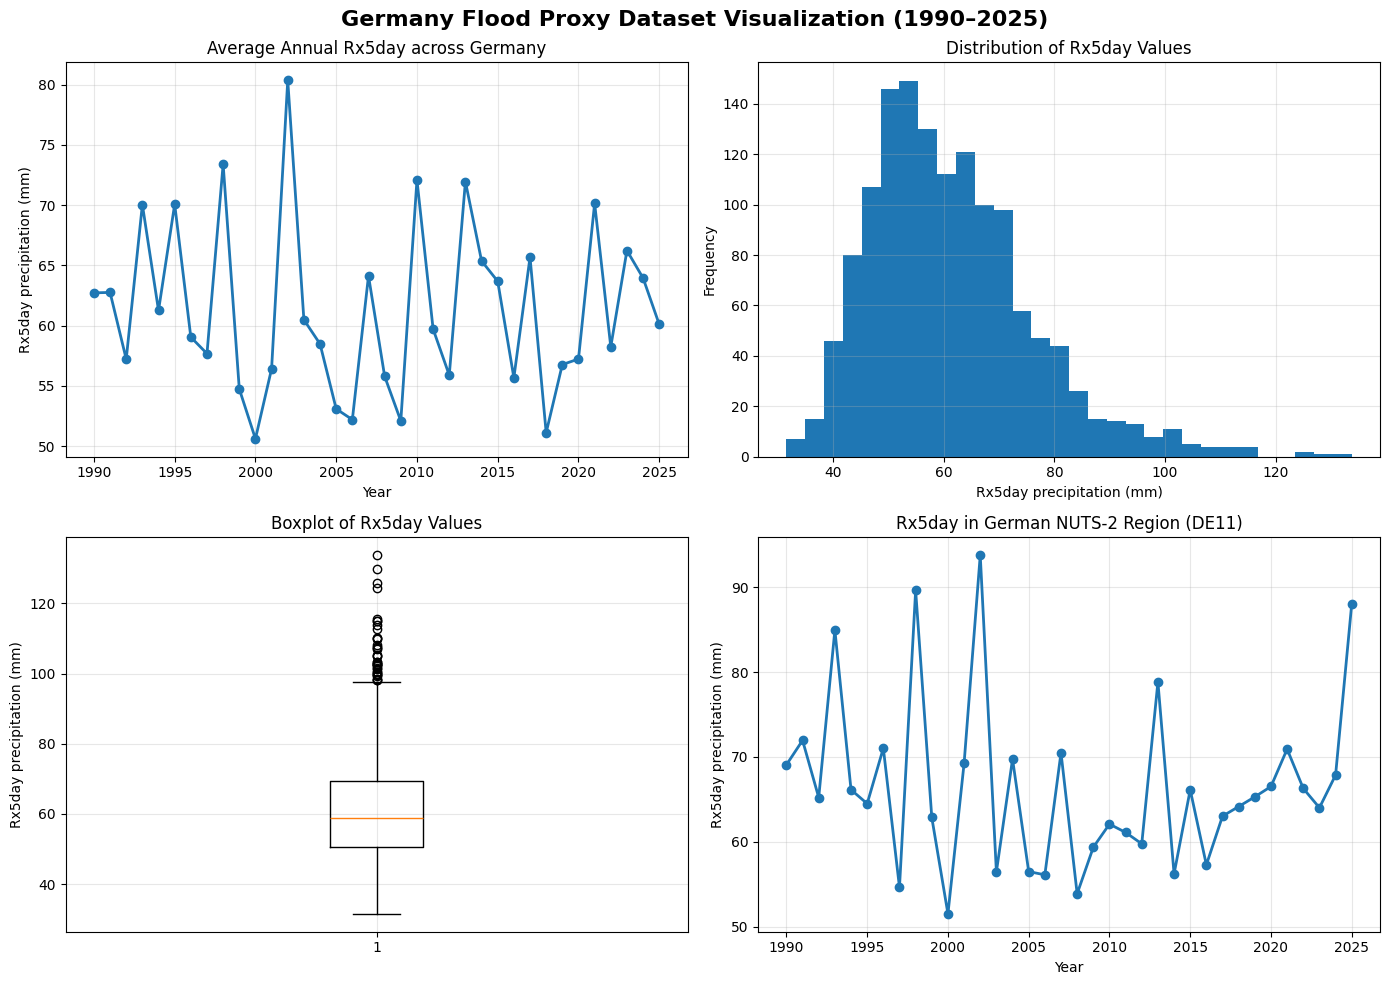

In [34]:
# =======================================================
# Visualize Germany flood proxy dataset (1990–2025)
# Four plots in one 2x2 canvas
# =======================================================

# Prepare data
germany_flood_mean = germany_flood.mean(dim="nuts")

values = germany_flood.values.flatten()
values = values[~np.isnan(values)]

example_region = "DE11" if "DE11" in germany_flood["nuts"].values else germany_flood["nuts"].values[0]
region_flood = germany_flood.sel(nuts=example_region)

# Create 2x2 plot canvas
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Average annual Rx5day across Germany
axes[0, 0].plot(
    germany_flood_mean["time"].dt.year,
    germany_flood_mean,
    marker="o",
    linewidth=2
)
axes[0, 0].set_title("Average Annual Rx5day across Germany")
axes[0, 0].set_xlabel("Year")
axes[0, 0].set_ylabel("Rx5day precipitation (mm)")
axes[0, 0].grid(alpha=0.3)

# 2. Distribution of Rx5day values
axes[0, 1].hist(
    values,
    bins=30
)
axes[0, 1].set_title("Distribution of Rx5day Values")
axes[0, 1].set_xlabel("Rx5day precipitation (mm)")
axes[0, 1].set_ylabel("Frequency")
axes[0, 1].grid(alpha=0.3)

# 3. Boxplot
axes[1, 0].boxplot(values)
axes[1, 0].set_title("Boxplot of Rx5day Values")
axes[1, 0].set_ylabel("Rx5day precipitation (mm)")
axes[1, 0].grid(alpha=0.3)

# 4. Example German NUTS-2 region
axes[1, 1].plot(
    region_flood["time"].dt.year,
    region_flood,
    marker="o",
    linewidth=2
)
axes[1, 1].set_title(f"Rx5day in German NUTS-2 Region ({example_region})")
axes[1, 1].set_xlabel("Year")
axes[1, 1].set_ylabel("Rx5day precipitation (mm)")
axes[1, 1].grid(alpha=0.3)

# Overall title and layout
fig.suptitle(
    "Germany Flood Proxy Dataset Visualization (1990–2025)",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

#### Visualization Summary


The exploratory visualizations confirm that:

- Rx5day exhibits substantial interannual variability across Germany (1990–2025).
- Extreme precipitation events are infrequent but clearly distinguishable.
- Regional differences among German NUTS-2 regions are well represented.
- The dataset provides a suitable flood hazard proxy for AI-based climate risk modelling.

##### Implications for AI Model Development

The dataset will be retained in its original physical units within the raw data repository.

During feature engineering, it will be standardized together with the remaining climate variables before training the Feed-Forward Neural Network (FFNN), while preserving the original dataset for reproducibility.

##### Next Processing Step


The Germany subset (1990–2025) has been successfully extracted.

Remaining workflow:

- Extract the remaining climate hazard datasets.
- Merge all climate variables into a master dataset.
- Perform feature engineering and standardization.
- Build the AI-ready modelling dataset.
- Train and evaluate the Feed-Forward Neural Network (FFNN).